# Домашнее задание: подбор гиперпараметров бустинга и интерпретация модели с SHAP

**Ожидаемое время решения:** 1–1.5 часа.

## Задание

1. Постройте модель градиентного бустинга (LightGBM) на предложенном датасете, подобрав гиперпараметры с помощью Optuna. Исследуйте результаты подбора:
   1. Постройте **parallel coordinate plot** — какие гиперпараметры, судя по графику, можно зафиксировать (не тюнить), а какие критически важны?
   2. Постройте **contour plot** для пары наиболее важных гиперпараметров — хорошо ли подобрана сетка (границы) поиска, или оптимум упирается в край диапазона?
2. Исследуйте SHAP-значения обученной модели:
   1. По **beeswarm** и/или **bar plot** определите, какие признаки являются шумовыми (не влияют на предсказание).
   2. По **dependence plot** найдите интересные попарные взаимодействия признаков.

## Датасет

Мы работаем с синтетическим датасетом **кредитного скоринга** (предсказание дефолта заёмщика).

Формат сдачи: заполненный ноутбук `homework.ipynb`, который можно запустить целиком (Run All) без ошибок.

## 0. Импорт библиотек и генерация датасета

Ниже — готовый код для генерации датасета. Его не нужно менять, просто выполните ячейки.

In [3]:
# pip install lightgbm optuna plotly shap seaborn pandas numpy matplotlib scikit-learn

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
import lightgbm as lgb

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

df = pd.read_csv("credit_default_dataset.csv")
print(df.shape)
print(f"Доля дефолтов: {df['default'].mean():.3f}")
df.head()

(5000, 10)
Доля дефолтов: 0.329


,credit_score,debt_to_income,num_late_payments,employment_years,loan_amount,age,num_dependents,random_noise_1,random_noise_2,default
0,791.124188,0.392597,0,11.983732,30789.448624,40.644553,1,-0.459744,-0.302889,0
1,682.012577,0.048017,2,2.989243,16185.904729,63.539670,0,-0.101710,-0.477970,0
2,728.299039,0.220371,2,1.969566,47967.595997,39.928274,1,-0.101684,-0.676613,0
3,829.271456,0.573167,4,5.233681,33381.566076,62.364786,2,-1.101363,-0.439043,1
4,799.404639,0.451384,4,4.912667,9389.584941,32.648320,0,-0.950643,0.333650,0


### Разбиение на train/test

In [5]:
feature_cols = [c for c in df.columns if c != 'default']
X = df[feature_cols]
y = df['default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)
X_train.shape, X_test.shape

((3500, 9), (1500, 9))

## 1. Подбор гиперпараметров LightGBM с помощью Optuna (4 балла)

**Задание:** напишите objective-функцию для Optuna, которая обучает `lgb.train` с подсказанными (`trial.suggest_*`) гиперпараметрами и возвращает AUC на валидационной выборке (`X_test`, `y_test`). Используйте early stopping.

Рекомендуемое пространство поиска (можно скорректировать):
- `num_leaves`: int, [10, 200]
- `learning_rate`: float, [0.01, 0.3], log scale
- `feature_fraction`: float, [0.5, 1.0]
- `bagging_fraction`: float, [0.5, 1.0]
- `bagging_freq`: int, [1, 10]
- `lambda_l1`: float, [1e-8, 10.0], log scale
- `lambda_l2`: float, [1e-8, 10.0], log scale

Запустите не менее 50 trials.

In [6]:
import optuna

train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_test, label=y_test, reference=train_data)


def objective(trial):
    params = {
        'objective': 'binary',
        'metric': 'auc',
        'verbosity': -1,
        'boosting_type': 'gbdt',
        'random_state': RANDOM_STATE,
        # TODO: задайте гиперпараметры через trial.suggest_*
        'num_leaves': trial.suggest_int('nl', 10, 200),       # TODO
        'learning_rate': trial.suggest_float('lr', 0.001, 0.3, log = True),    # TODO
        'feature_fraction': trial.suggest_float('ff', 0.5, 1, step=0.1), # TODO
        'bagging_fraction': trial.suggest_float('bf', 0.5, 1, step=0.1), # TODO
        'bagging_freq': trial.suggest_int('bfreq', 1, 10),     # TODO
        'lambda_l1': trial.suggest_float('ll1', 1e-8, 10, log = True),        # TODO
        'lambda_l2': trial.suggest_float('ll2', 1e-8, 10, log = True),        # TODO
    }

    # TODO: обучите модель с early stopping и верните AUC на валидации
    model = lgb.train(params=params, train_set=train_data, valid_sets=[valid_data], callbacks=[lgb.early_stopping(stopping_rounds=5)])
    auc = roc_auc_score(y_test, model.predict(X_test))
    return auc


# TODO: создайте study и запустите optimize (n_trials >= 50)
study = optuna.create_study(direction = 'maximize')
study.optimize(objective, n_trials=100)

print("Best params:", study.best_params)
print("Best AUC:", study.best_value)

[I 2026-08-16 21:22:40,997] A new study created in memory with name: no-name-d40f1b87-9123-4974-a8f4-e7832c3aa169


Training until validation scores don't improve for 5 rounds


[I 2026-08-16 21:22:41,406] Trial 0 finished with value: 0.807683940610453 and parameters: {'nl': 53, 'lr': 0.0011859288526445595, 'ff': 0.5, 'bf': 1.0, 'bfreq': 2, 'll1': 0.0035830630791703487, 'll2': 0.0055857331684160145}. Best is trial 0 with value: 0.807683940610453.


Early stopping, best iteration is:
[15]	valid_0's auc: 0.807684
Training until validation scores don't improve for 5 rounds


[I 2026-08-16 21:22:41,959] Trial 1 finished with value: 0.8063101897266799 and parameters: {'nl': 126, 'lr': 0.004201671508879291, 'ff': 0.9, 'bf': 0.6, 'bfreq': 4, 'll1': 1.6435297453901485e-06, 'll2': 0.1744210458418734}. Best is trial 0 with value: 0.807683940610453.


...

Training until validation scores don't improve for 5 rounds
Early stopping, best iteration is:
[16]	valid_0's auc: 0.811415
Training until validation scores don't improve for 5 rounds


[I 2026-08-16 21:23:01,869] Trial 97 finished with value: 0.8146302454824343 and parameters: {'nl': 35, 'lr': 0.028044958855613658, 'ff': 0.5, 'bf': 0.9, 'bfreq': 5, 'll1': 1.1577680295646104e-07, 'll2': 0.02725939335582299}. Best is trial 59 with value: 0.8187696268111052.


Early stopping, best iteration is:
[21]	valid_0's auc: 0.81463
Training until validation scores don't improve for 5 rounds


[I 2026-08-16 21:23:02,094] Trial 98 finished with value: 0.805084489707947 and parameters: {'nl': 81, 'lr': 0.022071329682037233, 'ff': 0.5, 'bf': 0.8, 'bfreq': 5, 'll1': 5.448021956167684e-07, 'll2': 0.01220994099705013}. Best is trial 59 with value: 0.8187696268111052.
[I 2026-08-16 21:23:02,213] Trial 99 finished with value: 0.8100567830460609 and parameters: {'nl': 64, 'lr': 0.01794892484422019, 'ff': 0.5, 'bf': 0.9, 'bfreq': 4, 'll1': 2.3296173005301233e-08, 'll2': 0.006090145241353582}. Best is trial 59 with value: 0.8187696268111052.


Early stopping, best iteration is:
[25]	valid_0's auc: 0.805084
Training until validation scores don't improve for 5 rounds
Early stopping, best iteration is:
[9]	valid_0's auc: 0.810057
Best params: {'nl': 16, 'lr': 0.007874064888455145, 'ff': 0.6, 'bf': 0.9, 'bfreq': 8, 'll1': 0.0070861195765571025, 'll2': 0.13517928064067064}
Best AUC: 0.8187696268111052


### 1.1 Обучение финальной модели с лучшими параметрами

**Задание:** обучите LightGBM с параметрами `study.best_params` на полном train, сохраните модель в переменную `model_lgb` — она понадобится для SHAP-анализа далее.

In [7]:
best_params = study.best_params.copy()
best_params.update({'objective': 'binary', 'metric': 'auc', 'verbosity': -1, 'random_state': RANDOM_STATE})

# TODO: обучите финальную модель model_lgb с best_params
train_full = lgb.Dataset(X, label=y)
model_lgb = lgb.train(params=best_params, train_set=train_full )

# TODO: посчитайте и выведите AUC на train и test
print(f"Train:\n{roc_auc_score(y_train, model_lgb.predict(X_train))}\nTest:\n{roc_auc_score(y_test, model_lgb.predict(X_test))}")


Train:
0.9768516053851978
Test:
0.9736711175926727


### 1.2 Parallel coordinate plot

**Задание:** постройте parallel coordinate plot для `study`. Изучите график и ответьте письменно (в markdown-ячейке ниже): какие гиперпараметры, судя по графику, слабо влияют на итоговый AUC и их можно было бы зафиксировать на разумном значении по умолчанию, чтобы сократить пространство поиска?

In [8]:
from optuna.visualization import plot_parallel_coordinate

# TODO: постройте parallel coordinate plot
fig = plot_parallel_coordinate(study)
fig.show()

**Ваш ответ:** Судя по графику, меньше всего влияют bfreq, ff, ll1 и ll2, потому что линии к ним распределены +- равномерно, а значит, что вне зависимости от их значений модель может прийти к хорошей метрике, а значит, что их значения не особо влияют. Однако чтобы подтвердить наше утверждение рассмотрим ниже plot_param_importances, которое даст нам ещё больше информации о влиянии гиперпараметров.

### 1.3 Contour plot

**Задание:** выберите два гиперпараметра, которые (судя по `plot_param_importances`) сильнее всего влияют на метрику, и постройте для них contour plot. Ответьте: находится ли найденный оптимум внутри заданных границ поиска, или он «упирается» в край диапазона? Если упирается — как нужно было бы изменить границы поиска?

In [9]:
from optuna.visualization import plot_param_importances, plot_contour

# TODO: постройте plot_param_importances(study)
fig = plot_param_importances(study)
fig.show()
# TODO: выберите два наиболее важных гиперпараметра и постройте для них plot_contour(study, params=[...])
fig = plot_contour(study, params=['bfreq', 'nl'])
fig.show()

**Ваш ответ:** Оказалось, что, несмотря на parallel coordinate plot, bfreq оказался буквально самым важным гиперпараметром. Более того, мы знаем, что оптимальный roc-auc - это $\approx 0.818$, по нашей легенде это самый синий участок графика, видно, что он находится внутри графика и не прижимается к его границам, так как такие значения лежат в нижнем левом углу, но, приближаясь к левой границе, оно постепенно светлеет, а со всех остальных сторон оно изолировано меньшими значениями, аналогично с правым нижним углом, где-то чуть выше середины в левом верхнем углу тоже есть близкие значения, но они тоже со всех сторон изолированы, то есть нам не надо никак расширять границы поиска. Если бы оптимум упирался влево, то это было бы печально, потому что bfreq можно расширить только до нуля; если бы упирался вправо, то расширяли бы bfreq до больших значений; аналогично, если бы упирался вниз, то ничего бы сделать не смогли, а если вверх, то увеличивать nl.

## 2. Интерпретация модели с помощью SHAP (4 балла)

**Задание:** пересчитайте SHAP-значения для обученной модели `model_lgb` на тестовой выборке с помощью `shap.TreeExplainer`.

In [10]:
import shap

# TODO: создайте explainer
explainer = shap.TreeExplainer(model_lgb)

# TODO: посчитайте shap_values для X_test
shap_values = explainer.shap_values(X_test)

feature_names = feature_cols

c:\Users\temy2\AppData\Local\Programs\Python\Python310\lib\site-packages\shap\explainers\_tree.py:586: UserWarning:

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray



### 2.1 Beeswarm / bar plot — поиск шумовых признаков

**Задание:** постройте beeswarm plot (`shap.summary_plot`) и bar plot (агрегированная важность). Определите, какие признаки являются шумовыми (SHAP value близок к нулю для всех наблюдений). Совпадает ли ваш список с тем, что вы ожидали, глядя на названия признаков?

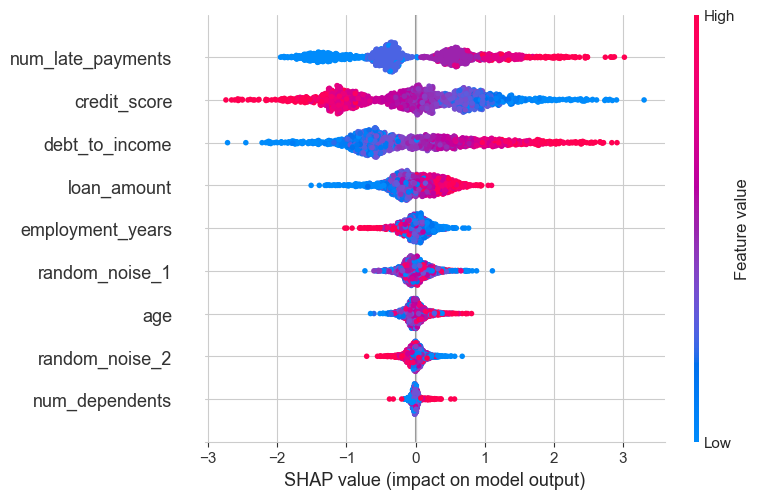

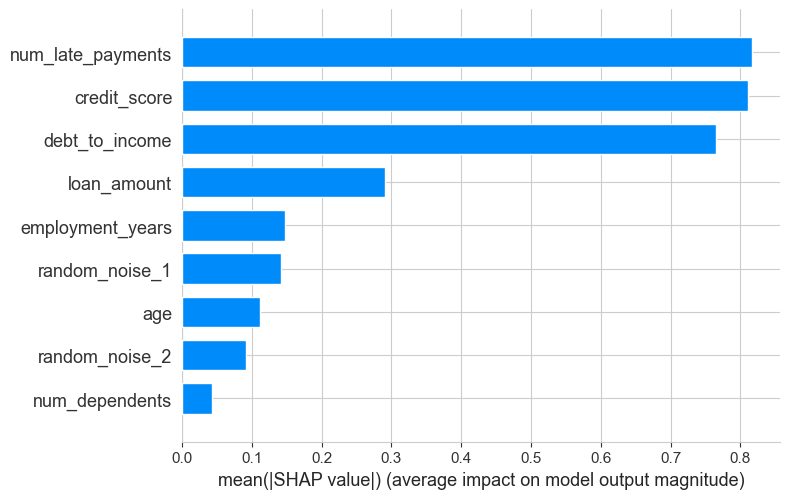

In [11]:
# TODO: постройте beeswarm plot
# shap.summary_plot(...)

shap.summary_plot(shap_values, X_test, feature_names=feature_cols, show = True)

# TODO: постройте bar plot (агрегированная важность)
# shap.summary_plot(..., plot_type='bar')

shap.summary_plot(shap_values, X_test, feature_names=feature_cols, show = True, plot_type='bar')

**Ваш ответ:** Судя по графику, 5 признаков с конца являются шумовыми: num_dependents, random_noise_2 (сюрприз-сюрприз), age, random_noise_1 (сюрприз-сюрприз), employment_years, так как их шапы ближе всего к нулю, кроме того, loan_amount делает существенный скачок относительно employment_years, причём этот скачок даже больше чем скачок employment_years относительно num_dependets, так что, кажется, ровно с этой фичи и начинаются информативные. Кроме того, в их классификации помогают две изначально шумовых фичи, понятно, что фичи, которые близки к ним по шапам не могут отличаться большей информативностью, чем шум. В целом список действительно близок к тому списку, который ожидаешь увидеть, смотря на названия, единственное, что мне казалось, что возраст должен быть информативнее обоих шумов, а оказалось, что только одного, но понятно, что первые 4 сверху фичей напрямую относятся к тому, что мы предсказываем, а поэтому и несут больше всего информации, а вот все все остальные фичи уже не так прямо влияют на таргет, поэтому и близки к шуму.

### 2.2 Dependence plot — поиск попарных взаимодействий

**Задание:** постройте dependence plot для 2-3 наиболее важных признаков (по умолчанию SHAP сам подберёт цвет по признаку с наибольшим взаимодействием). Найдите признак, у которого зависимость SHAP value от значения самого признака выглядит по-разному в зависимости от цвета (значения второго признака) — это и есть взаимодействие. Дополнительно постройте dependence plot с явно заданным `interaction_index`, чтобы проверить гипотезу о конкретной паре признаков.

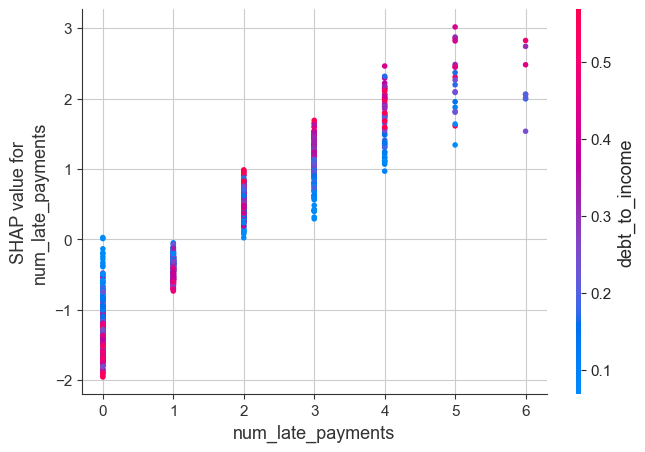

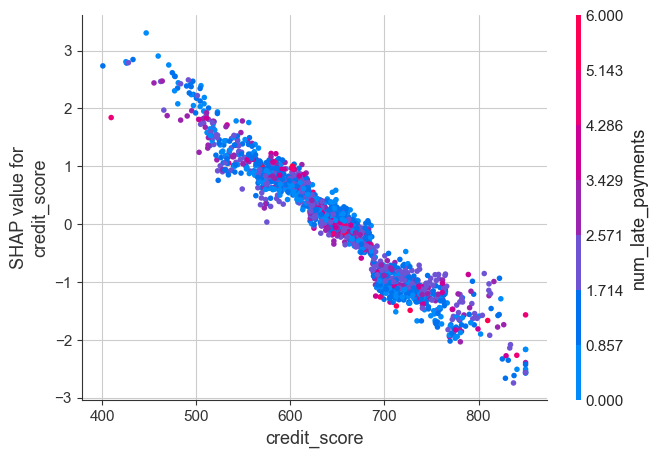

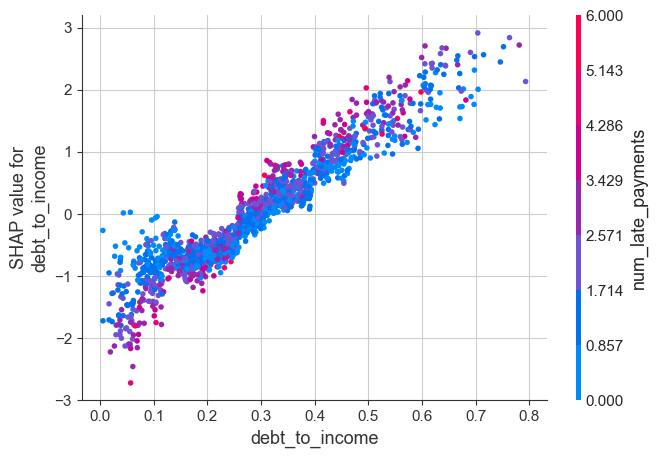

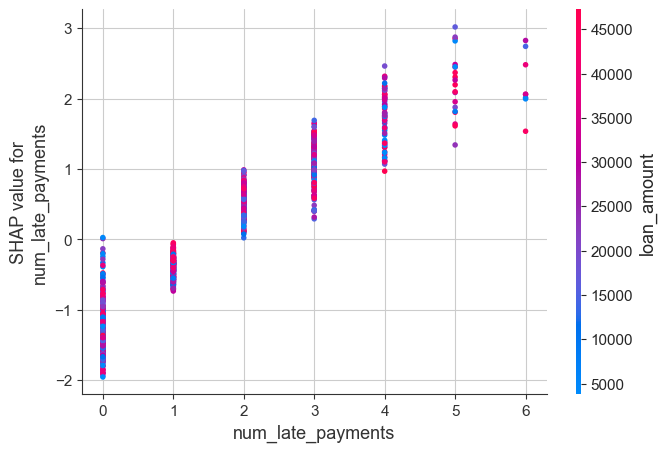

In [23]:
# TODO: постройте dependence plot для наиболее важного признака (по умолчанию)
# shap.dependence_plot(..., shap_values, X_test, feature_names=feature_names)
shap.dependence_plot('num_late_payments', shap_values, X_test, feature_names=feature_names, show = True)
shap.dependence_plot('credit_score', shap_values, X_test, feature_names=feature_names, show = True)
shap.dependence_plot('debt_to_income', shap_values, X_test, feature_names=feature_names, show = True)

# TODO: постройте dependence plot с явно заданным interaction_index для проверки конкретной гипотезы
# shap.dependence_plot(..., shap_values, X_test, feature_names=feature_names, interaction_index=...)
shap.dependence_plot('num_late_payments', shap_values, X_test, feature_names=feature_names, show = True, interaction_index=4)

**Ваш ответ:** Как и предполагалось, наиболее информативные по шапам фичи больше всего взаимодействуют друг с другом, причём даже по такой схеме:

```credit_score``` --> ```num_late_payments``` <--> ```debt_to_income```, где (1) --> (2) значит, что первый больше всего взаимодействует со вторым. Однако интересно ещё проверить, как взаимодействуют ```num_late_payments``` с ```loan_amount```, оказалось, что до какого-то момента размер долга сильно влияет на количество просрочек: чем в среднем больше размер долга, тем больше количество просрочек, однако на количестве просрочек = 6 оказалось, что в среднем у них относительно не очень большой размер долга, что возможно свидетельтсвует о том, что чем меньше размер долга, тем безответственнее заёмщики к нему относится, потому что до этого момента сохранялась тендеция, что чем больше просрочка, тем больше и околокрасных (околомаксимальный размер долго) и тем больше визуально средний размер долга.

## 3. Итоговые выводы (3 балла)

Кратко (в виде bullet points) резюмируйте:
- Какие гиперпараметры оказались важны, а какие можно было не тюнить?
- Была ли сетка поиска гиперпараметров задана удачно?
- Какие признаки оказались шумовыми?
- Какое взаимодействие признаков вы обнаружили и согласуется ли оно с вашей интуицией о кредитном риске?

**Ваш ответ:** _todo_